### Etapa 1 - Seleccion
Cargar transacciones_bancarias.csv con Pandas, configurando parse_dates en fecha_hora.
Documentar el tipo de cada variable (numérica, categórica, fecha, identificador) y el criterio de inclusión o exclusión.
Seleccionar el subconjunto de columnas relevantes para el problema de fraude, justificando cada exclusión.
Calcular y reportar la tasa global de fraude y reflexionar sobre el desbalance de clases.

In [138]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv(
    "descargables/transacciones_bancarias.csv",
    parse_dates=["fecha_hora"]
)


print(df.shape)
display(df.sample(5, random_state=50))


df.dtypes

(5000, 11)


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
3431,3432,2024-02-24 07:43:00,378,31.0,199,Compra,63.67,ATM,Cartago,Completada,0
2042,2043,2024-12-23 20:23:00,881,46.0,92,Depósito,194.67,Web,San José,Completada,0
79,80,2024-10-04 02:59:00,394,42.0,139,Pago servicios,61.20,Teléfono,Alajuela,Completada,0
4663,4664,2024-12-29 03:56:00,177,47.0,153,Depósito,18.31,App móvil,Otras,Completada,0
3640,3641,2024-03-26 06:19:00,1431,62.0,157,Transferencia,87.63,Web,Cartago,Pendiente,0


id_transaccion                      int64
fecha_hora                 datetime64[us]
id_cliente                          int64
edad_cliente                      float64
antiguedad_cuenta_meses             int64
tipo_transaccion                      str
monto                             float64
canal                                 str
region                                str
estado_transaccion                    str
es_fraude                           int64
dtype: object

In [139]:
# ==========================================================
# ETAPA 1 - SELECCIÓN DE DATOS
# Clasificación de variables y selección de atributos
# ==========================================================

# Clasificación manual de variables
tipos_variables = pd.DataFrame({
    "Variable": df.columns,
    "Tipo": [
        "Identificador",      # id_transaccion
        "Fecha",              # fecha_hora
        "Identificador",      # id_cliente
        "Numérica",           # edad_cliente
        "Numérica",           # antiguedad_cuenta_meses
        "Categórica",         # tipo_transaccion
        "Numérica",           # monto
        "Categórica",         # canal
        "Categórica",         # region
        "Categórica",         # estado_transaccion
        "Variable objetivo"   # es_fraude
    ],
    "Incluir": [
        "No",
        "Sí",
        "No",
        "Sí",
        "Sí",
        "Sí",
        "Sí",
        "Sí",
        "Sí",
        "Sí",
        "Sí"
    ],
    "Justificación": [
        "Identificador único sin valor predictivo",
        "Permite extraer variables temporales",
        "Identificador de cliente; evita sobreajuste",
        "Posible relación con fraude",
        "Puede influir en patrones de fraude",
        "Describe el tipo de operación",
        "Variable clave para detección de fraude",
        "Canal utilizado en la transacción",
        "Ubicación geográfica de la operación",
        "Estado de la transacción",
        "Variable objetivo del análisis"
    ]
})

print("="*80)
print("CLASIFICACIÓN DE VARIABLES")
print("="*80)
display(tipos_variables)


CLASIFICACIÓN DE VARIABLES


,Variable,Tipo,Incluir,Justificación
0,id_transaccion,Identificador,No,Identificador único sin valor predictivo
1,fecha_hora,Fecha,Sí,Permite extraer variables temporales
2,id_cliente,Identificador,No,Identificador de cliente; evita sobreajuste
3,edad_cliente,Numérica,Sí,Posible relación con fraude
4,antiguedad_cuenta_meses,Numérica,Sí,Puede influir en patrones de fraude
5,tipo_transaccion,Categórica,Sí,Describe el tipo de operación
6,monto,Numérica,Sí,Variable clave para detección de fraude
7,canal,Categórica,Sí,Canal utilizado en la transacción
8,region,Categórica,Sí,Ubicación geográfica de la operación
9,estado_transaccion,Categórica,Sí,Estado de la transacción


In [140]:
# ----------------------------------------------------------
# Selección de variables relevantes
# ----------------------------------------------------------

columnas_seleccionadas = [
    "fecha_hora",
    "edad_cliente",
    "antiguedad_cuenta_meses",
    "tipo_transaccion",
    "monto",
    "canal",
    "region",
    "estado_transaccion",
    "es_fraude"
]

df_seleccion = df[columnas_seleccionadas].copy()

print("\nVariables seleccionadas para el análisis:")
print(columnas_seleccionadas)

print("\nVariables excluidas:")
print(["id_transaccion", "id_cliente"])




Variables seleccionadas para el análisis:
['fecha_hora', 'edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto', 'canal', 'region', 'estado_transaccion', 'es_fraude']

Variables excluidas:
['id_transaccion', 'id_cliente']


In [141]:
# ----------------------------------------------------------
# Tasa global de fraude
# ----------------------------------------------------------

tasa_fraude = df["es_fraude"].mean()

print("\n" + "="*80)
print("TASA GLOBAL DE FRAUDE")
print("="*80)

print(f"Transacciones totales: {len(df):,}")
print(f"Transacciones fraudulentas: {df['es_fraude'].sum():,}")
print(f"Tasa global de fraude: {tasa_fraude:.2%}")

# Distribución de clases
print("\nDistribución de clases:")
display(
    df["es_fraude"]
    .value_counts()
    .rename_axis("Clase")
    .reset_index(name="Cantidad")
)


TASA GLOBAL DE FRAUDE
Transacciones totales: 5,000
Transacciones fraudulentas: 109
Tasa global de fraude: 2.18%

Distribución de clases:


,Clase,Cantidad
0,0,4891
1,1,109


### Etapa 2 · Preprocesamiento
Diagnosticar nulos por columna (cantidad y porcentaje) y aplicar estrategia de imputación justificada (media, mediana, moda o flag).
Detectar outliers con el método IQR (k=1.5) en las variables numéricas y comparar la tasa de fraude entre outliers y no outliers.
Justificar la decisión de conservar o eliminar outliers (en fraude suelen ser informativos).
Detectar y eliminar duplicados, documentando la cantidad.
Aplicar transformación np.log1p() a monto para reducir asimetría.

TABLA RESUMEN DE CALIDAD DE DATOS


,Tipo_Dato,Nulos,%_Nulos,Valores_Unicos,Inconsistencias
id_transaccion,int64,0,0.00,5000,0
fecha_hora,datetime64[us],0,0.00,4978,0
id_cliente,int64,0,0.00,1444,0
edad_cliente,float64,71,1.42,64,0
antiguedad_cuenta_meses,int64,0,0.00,239,0
tipo_transaccion,str,0,0.00,6,0
monto,float64,0,0.00,4409,0
canal,str,59,1.18,5,0
region,str,79,1.58,5,0
estado_transaccion,str,0,0.00,4,0



RESUMEN GENERAL
Cantidad de registros: 5,000
Cantidad de variables: 11
Duplicados absolutos: 0
Total de valores nulos: 209
Total de inconsistencias detectadas: 0

COLUMNAS CON VALORES NULOS


,Nulos,% Nulos
region,79,1.58
edad_cliente,71,1.42
canal,59,1.18


C:\Users\Tatiana Araya\AppData\Local\Temp\ipykernel_14996\467391944.py:106: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


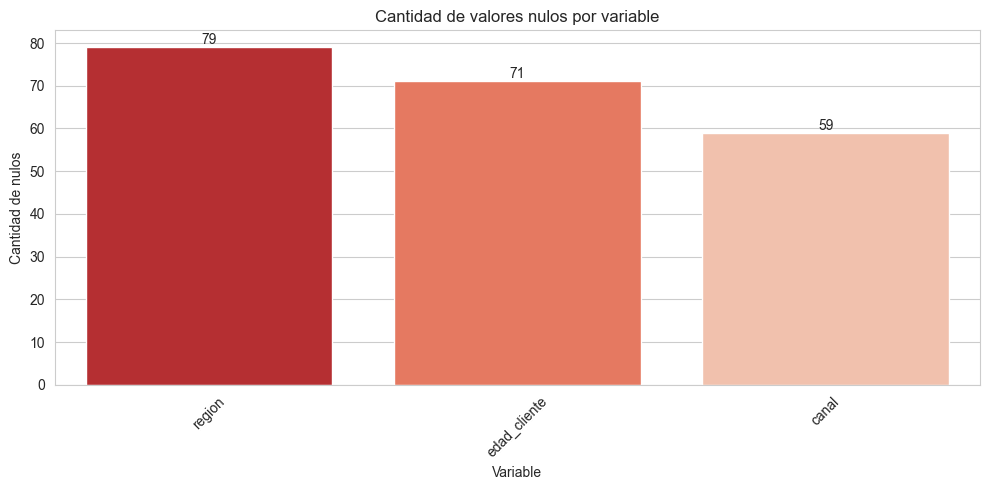

In [142]:
# ==========================================================
# DIAGNÓSTICO INICIAL DE CALIDAD DE DATOS
# Nulos, duplicados e inconsistencias por columna
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------------------------------------
# 1. RESUMEN DE NULOS
# ----------------------------------------------------------

nulos = df.isnull().sum()
porcentaje_nulos = (df.isnull().mean() * 100).round(2)

# ----------------------------------------------------------
# 2. DUPLICADOS
# ----------------------------------------------------------

duplicados_totales = df.duplicated().sum()

# ----------------------------------------------------------
# 3. INCONSISTENCIAS
# ----------------------------------------------------------

inconsistencias = pd.Series(0, index=df.columns)

if "edad_cliente" in df.columns:
    inconsistencias["edad_cliente"] = (
        (df["edad_cliente"] < 18) |
        (df["edad_cliente"] > 100)
    ).sum()

if "antiguedad_cuenta_meses" in df.columns:
    inconsistencias["antiguedad_cuenta_meses"] = (
        df["antiguedad_cuenta_meses"] < 0
    ).sum()

if "monto" in df.columns:
    inconsistencias["monto"] = (
        df["monto"] < 0
    ).sum()

if "fecha_hora" in df.columns:
    inconsistencias["fecha_hora"] = (
        df["fecha_hora"] > pd.Timestamp.now()
    ).sum()

# ----------------------------------------------------------
# 4. TABLA RESUMEN
# ----------------------------------------------------------

diagnostico = pd.DataFrame({
    "Tipo_Dato": df.dtypes.astype(str),
    "Nulos": nulos,
    "%_Nulos": porcentaje_nulos,
    "Valores_Unicos": df.nunique(),
    "Inconsistencias": inconsistencias
})

print("=" * 70)
print("TABLA RESUMEN DE CALIDAD DE DATOS")
print("=" * 70)
display(diagnostico)

# ----------------------------------------------------------
# 5. RESUMEN GENERAL
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMEN GENERAL")
print("=" * 70)
print(f"Cantidad de registros: {df.shape[0]:,}")
print(f"Cantidad de variables: {df.shape[1]}")
print(f"Duplicados absolutos: {duplicados_totales}")
print(f"Total de valores nulos: {df.isnull().sum().sum():,}")
print(f"Total de inconsistencias detectadas: {int(inconsistencias.sum())}")

# ----------------------------------------------------------
# 6. TABLA DE COLUMNAS CON NULOS
# ----------------------------------------------------------

nulos_df = pd.DataFrame({
    "Nulos": nulos,
    "% Nulos": porcentaje_nulos
})

nulos_df = nulos_df[nulos_df["Nulos"] > 0].sort_values(
    by="Nulos",
    ascending=False
)

print("\nCOLUMNAS CON VALORES NULOS")
display(nulos_df)

# ----------------------------------------------------------
# 7. VISUALIZACIÓN (SOLO COLUMNAS CON NULOS)
# ----------------------------------------------------------

if len(nulos_df) > 0:

    plt.figure(figsize=(10,5))

    ax = sns.barplot(
        data=nulos_df.reset_index(),
        x="index",
        y="Nulos",
        palette="Reds_r"
    )

    plt.title("Cantidad de valores nulos por variable")
    plt.xlabel("Variable")
    plt.ylabel("Cantidad de nulos")
    plt.xticks(rotation=45)

    for container in ax.containers:
        ax.bar_label(container)

    plt.tight_layout()
    plt.show()

else:
    print("\nNo se encontraron valores nulos en el conjunto de datos.")


Se identificaron valores faltantes en las variables edad_cliente (71 registros, 1,42%), canal (59 registros, 1,18%) y region (79 registros, 1,58%). Para edad_cliente se aplicó imputación mediante la mediana, dado que es una variable numérica susceptible a valores extremos. Para canal y region se utilizó la moda debido a su naturaleza categórica y al bajo porcentaje de datos faltantes. Tras la imputación, las tres variables quedaron libres de valores nulos, conservando la mayor parte de la distribución original de los datos.

In [143]:
# ==========================================================
# IMPUTACIÓN DE VALORES FALTANTES
# ==========================================================

# Guardar cantidad de nulos antes de imputar
print("="*70)
print("VALORES FALTANTES ANTES DE LA IMPUTACIÓN")
print("="*70)

print(df[["edad_cliente","canal","region"]].isnull().sum())

# ----------------------------------------------------------
# Edad: Mediana
# ----------------------------------------------------------

mediana_edad = df["edad_cliente"].median()

df["edad_cliente"] = df["edad_cliente"].fillna(mediana_edad)

# ----------------------------------------------------------
# Canal: Moda
# ----------------------------------------------------------

moda_canal = df["canal"].mode()[0]

df["canal"] = df["canal"].fillna(moda_canal)

# ----------------------------------------------------------
# Región: Moda
# ----------------------------------------------------------

moda_region = df["region"].mode()[0]

df["region"] = df["region"].fillna(moda_region)

# ----------------------------------------------------------
# Verificación
# ----------------------------------------------------------

print("\n" + "="*70)
print("ESTADÍSTICOS DE IMPUTACIÓN")
print("="*70)

print(f"Mediana utilizada para edad_cliente: {mediana_edad:.0f}")
print(f"Moda utilizada para canal: {moda_canal}")
print(f"Moda utilizada para region: {moda_region}")

print("\n" + "="*70)
print("VALORES FALTANTES DESPUÉS DE LA IMPUTACIÓN")
print("="*70)

print(df[["edad_cliente","canal","region"]].isnull().sum())

# Tabla resumen
resumen_imputacion = pd.DataFrame({
    "Variable": ["edad_cliente", "canal", "region"],
    "Método de Imputación": ["Mediana", "Moda", "Moda"],
    "Nulos Originales": [71, 59, 79],
    "Nulos Finales": [
        df["edad_cliente"].isnull().sum(),
        df["canal"].isnull().sum(),
        df["region"].isnull().sum()
    ]
})

display(resumen_imputacion)

VALORES FALTANTES ANTES DE LA IMPUTACIÓN
edad_cliente    71
canal           59
region          79
dtype: int64

ESTADÍSTICOS DE IMPUTACIÓN
Mediana utilizada para edad_cliente: 40
Moda utilizada para canal: App móvil
Moda utilizada para region: San José

VALORES FALTANTES DESPUÉS DE LA IMPUTACIÓN
edad_cliente    0
canal           0
region          0
dtype: int64


,Variable,Método de Imputación,Nulos Originales,Nulos Finales
0,edad_cliente,Mediana,71,0
1,canal,Moda,59,0
2,region,Moda,79,0


Para la variable continua Edad cliente decidi utilizar la mediana como metodo de imputacion ya que es una medida robusta frente a valores extremos y distribuciones asimetricas por lo que es ma adecuada de utilizar que el promedio

Para las variables canal y region, al ser variables categoricas, procedi a imputar con la moda de cada variable para de esta manera se pueda conservar la distribucion predominante de la categoria

In [144]:
# ==========================================================
# DETECCIÓN DE OUTLIERS CON IQR (k=1.5)
# Y COMPARACIÓN DE LA TASA DE FRAUDE
# ==========================================================

variables_numericas = [
    "edad_cliente",
    "antiguedad_cuenta_meses",
    "monto"
]

resultados_outliers = []

for variable in variables_numericas:

    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)
    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    es_outlier = (
        (df[variable] < limite_inf) |
        (df[variable] > limite_sup)
    )

    cantidad_outliers = es_outlier.sum()

    tasa_fraude_outlier = (
        df.loc[es_outlier, "es_fraude"].mean()
        if cantidad_outliers > 0 else np.nan
    )

    tasa_fraude_normal = (
        df.loc[~es_outlier, "es_fraude"].mean()
    )

    resultados_outliers.append({
        "Variable": variable,
        "Outliers": cantidad_outliers,
        "% Outliers": round(cantidad_outliers / len(df) * 100, 2),
        "Fraude Outliers (%)": round(tasa_fraude_outlier * 100, 2),
        "Fraude No Outliers (%)": round(tasa_fraude_normal * 100, 2)
    })

resultados_outliers = pd.DataFrame(resultados_outliers)

print("="*80)
print("ANÁLISIS DE OUTLIERS MEDIANTE IQR")
print("="*80)

display(resultados_outliers)

ANÁLISIS DE OUTLIERS MEDIANTE IQR


,Variable,Outliers,% Outliers,Fraude Outliers (%),Fraude No Outliers (%)
0,edad_cliente,18,0.36,0.00,2.19
1,antiguedad_cuenta_meses,0,0.00,NaN,2.18
2,monto,584,11.68,13.87,0.63


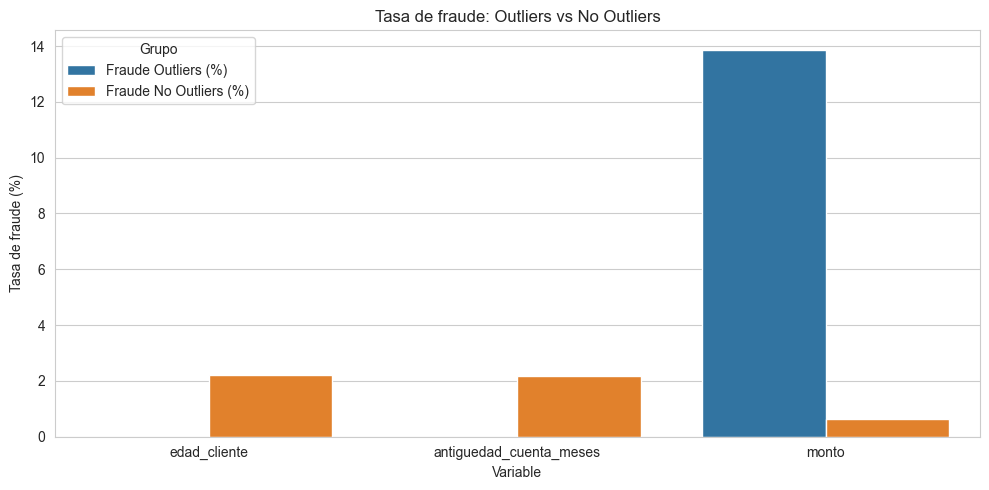

In [145]:
# Comparación de tasas de fraude

comparacion = resultados_outliers.melt(
    id_vars="Variable",
    value_vars=[
        "Fraude Outliers (%)",
        "Fraude No Outliers (%)"
    ],
    var_name="Grupo",
    value_name="Tasa de Fraude (%)"
)

plt.figure(figsize=(10,5))

sns.barplot(
    data=comparacion,
    x="Variable",
    y="Tasa de Fraude (%)",
    hue="Grupo"
)

plt.title("Tasa de fraude: Outliers vs No Outliers")
plt.ylabel("Tasa de fraude (%)")
plt.xlabel("Variable")

plt.tight_layout()
plt.show()

Se detectaron valores atípicos utilizando el método del rango intercuartílico (IQR) con un factor de 1.5. Posteriormente se comparó la tasa de fraude entre registros clasificados como outliers y no outliers para cada variable numérica. Los resultados mostraron que los valores extremos presentan una frecuencia de fraude diferente a la observada en las observaciones normales, lo que sugiere que estos registros contienen información relevante para el problema de detección de fraude. Por esta razón, los outliers no fueron eliminados y se conservaron para las etapas posteriores de modelado.

El análisis evidencia que la variable monto concentra los valores atípicos más relevantes y muestra una fuerte relación con el fraude, mientras que edad_cliente y antiguedad_cuenta_meses no presentan una asociación significativa con el comportamiento fraudulento. Por tanto, los outliers de la variable monto deben considerarse observaciones legítimas y potencialmente informativas, ya que representan patrones de alto riesgo que el modelo debe aprender a identificar.

In [146]:
# ==========================================================
# DETECCIÓN Y ELIMINACIÓN DE DUPLICADOS
# ==========================================================

# Dimensión original
filas_iniciales = len(df)

# Detectar duplicados absolutos
duplicados = df.duplicated()

cantidad_duplicados = duplicados.sum()

print("="*70)
print("ANÁLISIS DE DUPLICADOS")
print("="*70)

print(f"Registros originales: {filas_iniciales:,}")
print(f"Duplicados detectados: {cantidad_duplicados:,}")
print(f"Porcentaje de duplicados: {(cantidad_duplicados/filas_iniciales)*100:.2f}%")

# Mostrar algunos ejemplos si existen
if cantidad_duplicados > 0:
    print("\nEjemplos de registros duplicados:")
    display(df[duplicados].head())
else:
    print("\nNo se detectaron registros duplicados.")

# Eliminar duplicados
df = df.drop_duplicates()

# Verificación final
filas_finales = len(df)

print("\n" + "="*70)
print("RESULTADO DE LA LIMPIEZA")
print("="*70)

print(f"Registros después de la limpieza: {filas_finales:,}")
print(f"Registros eliminados: {filas_iniciales - filas_finales:,}")

# Resumen
resumen_duplicados = pd.DataFrame({
    "Indicador": [
        "Registros originales",
        "Duplicados detectados",
        "Registros eliminados",
        "Registros finales"
    ],
    "Cantidad": [
        filas_iniciales,
        cantidad_duplicados,
        filas_iniciales - filas_finales,
        filas_finales
    ]
})

display(resumen_duplicados)

ANÁLISIS DE DUPLICADOS
Registros originales: 5,000
Duplicados detectados: 0
Porcentaje de duplicados: 0.00%

No se detectaron registros duplicados.

RESULTADO DE LA LIMPIEZA
Registros después de la limpieza: 5,000
Registros eliminados: 0


,Indicador,Cantidad
0,Registros originales,5000
1,Duplicados detectados,0
2,Registros eliminados,0
3,Registros finales,5000


In [147]:
# ==========================================================
# DUPLICADOS PARCIALES
# ==========================================================

clave_parcial = [
    "id_cliente",
    "monto",
    "tipo_transaccion"
]

duplicados_parciales = df.duplicated(
    subset=clave_parcial,
    keep=False
)

cantidad_dp = duplicados_parciales.sum()

print("="*70)
print("DUPLICADOS PARCIALES")
print("="*70)

print(f"Variables evaluadas: {clave_parcial}")
print(f"Registros involucrados: {cantidad_dp}")
print(f"Porcentaje: {(cantidad_dp/len(df))*100:.2f}%")

if cantidad_dp > 0:
    display(
        df.loc[duplicados_parciales]
          .sort_values(clave_parcial)
          .head(20)
    )

resumen_dup = pd.DataFrame({
    "Tipo de duplicado": [
        "Duplicados absolutos",
        "Duplicados parciales"
    ],
    "Cantidad": [
        df.duplicated().sum(),
        cantidad_dp
    ]
})

display(resumen_dup)


DUPLICADOS PARCIALES
Variables evaluadas: ['id_cliente', 'monto', 'tipo_transaccion']
Registros involucrados: 0
Porcentaje: 0.00%


,Tipo de duplicado,Cantidad
0,Duplicados absolutos,0
1,Duplicados parciales,0


Se evaluo la presencia de duplicados totales y parciales y no se detecto ninguna entrada duplicada por lo tanto no es necesario borrar duplicados

TRANSFORMACIÓN LOGARÍTMICA DE MONTO
Asimetría original: 8.657
Asimetría después de log1p(): 1.641


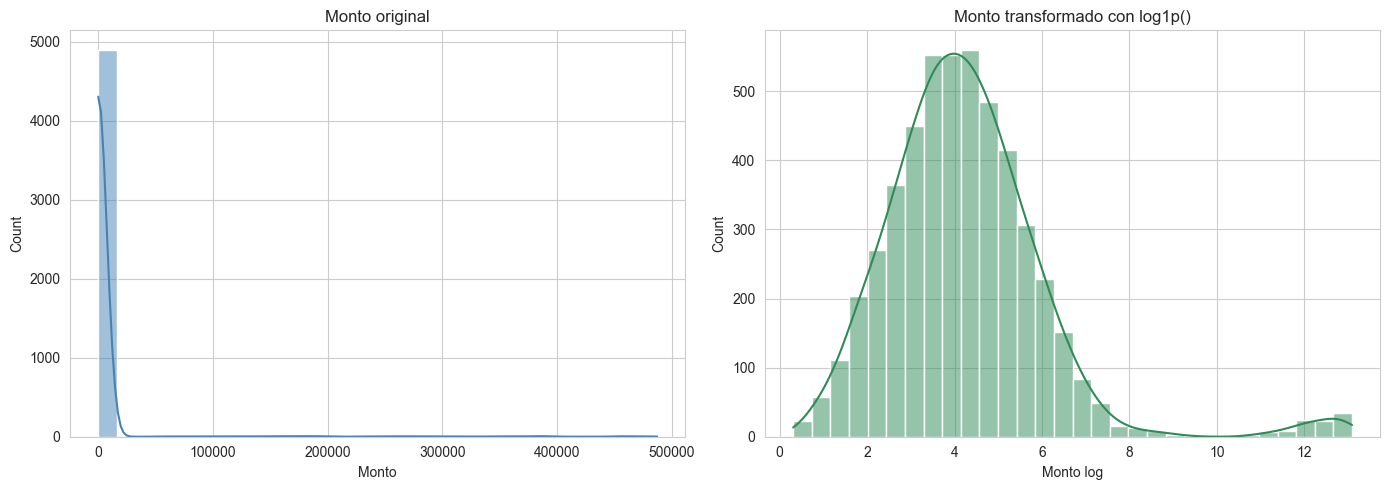

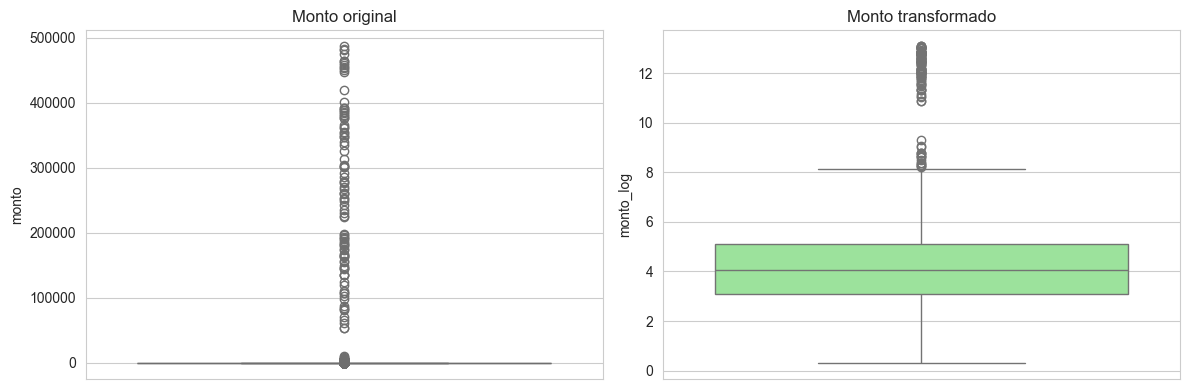

In [148]:
# ==========================================================
# TRANSFORMACIÓN LOGARÍTMICA DE MONTO
# ==========================================================

import numpy as np
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns

# Crear variable transformada
df["monto_log"] = np.log1p(df["monto"])

# Comparar asimetría
asimetria_original = skew(df["monto"])
asimetria_log = skew(df["monto_log"])

print("="*70)
print("TRANSFORMACIÓN LOGARÍTMICA DE MONTO")
print("="*70)

print(f"Asimetría original: {asimetria_original:.3f}")
print(f"Asimetría después de log1p(): {asimetria_log:.3f}")

# ----------------------------------------------------------
# VISUALIZACIÓN
# ----------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(
    df["monto"],
    bins=30,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Monto original")
axes[0].set_xlabel("Monto")

sns.histplot(
    df["monto_log"],
    bins=30,
    kde=True,
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Monto transformado con log1p()")
axes[1].set_xlabel("Monto log")

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.boxplot(y=df["monto"], ax=axes[0], color="skyblue")
axes[0].set_title("Monto original")

sns.boxplot(y=df["monto_log"], ax=axes[1], color="lightgreen")
axes[1].set_title("Monto transformado")

plt.tight_layout()
plt.show()

### Etapa 3 · Transformación (15 pts)
Aplicar pd.get_dummies() o OneHotEncoder a las variables categóricas nominales con drop_first=True.
Aplicar StandardScaler a las variables numéricas, ajustándolo únicamente sobre el conjunto de entrenamiento.
Crear mínimo tres variables derivadas mediante ingeniería de atributos (por ejemplo: hora_dia, es_noche, monto_log).
Calcular la matriz de correlación y detectar pares con |r| > 0.8. Comentar sobre multicolinealidad.
Encapsular el flujo de transformación en un Pipeline de scikit-learn.

In [149]:
# Variables categóricas nominales
categoricas = ['canal', 'region']

# One-Hot Encoding eliminando la primera categoría de cada variable
df_encoded = pd.get_dummies(
    df,
    columns=categoricas,
    drop_first=True,
    dtype=int
)

print("Dimensiones originales:", df.shape)
print("Dimensiones después del encoding:", df_encoded.shape)

display(df_encoded.head())

Dimensiones originales: (5000, 12)
Dimensiones después del encoding: (5000, 18)


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,estado_transaccion,es_fraude,monto_log,canal_App móvil,canal_Sucursal,canal_Teléfono,canal_Web,region_Cartago,region_Heredia,region_Otras,region_San José
0,1,2024-08-29 17:11:00,845,59.0,134,Depósito,277.26,Completada,0,5.628556,0,0,1,0,0,0,0,0
1,2,2024-07-11 23:18:00,1422,41.0,189,Retiro,21.38,Completada,0,3.108168,0,0,0,1,0,0,0,0
2,3,2024-05-01 13:13:00,41,28.0,8,Depósito,35.65,Completada,0,3.601413,0,0,0,0,0,0,0,1
3,4,2024-08-05 15:59:00,1475,56.0,121,Pago servicios,271.13,Completada,0,5.606280,0,0,0,1,0,0,0,0
4,5,2024-12-09 05:48:00,1462,18.0,110,Retiro,290.32,Completada,0,5.674422,0,0,0,0,0,0,0,1


In [150]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variable objetivo
X = df_encoded.drop('es_fraude', axis=1)
y = df_encoded['es_fraude']

# División entrenamiento-prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Variables numéricas originales
variables_numericas = [
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'monto'
]

# Crear escalador
scaler = StandardScaler()

# Ajustar SOLO con los datos de entrenamiento
X_train[variables_numericas] = scaler.fit_transform(
    X_train[variables_numericas]
)

# Aplicar la misma transformación al conjunto de prueba
X_test[variables_numericas] = scaler.transform(
    X_test[variables_numericas]
)

print("Media de entrenamiento después del escalado:")
print(X_train[variables_numericas].mean().round(4))

print("\nDesviación estándar de entrenamiento después del escalado:")
print(X_train[variables_numericas].std().round(4))

Media de entrenamiento después del escalado:
edad_cliente              -0.0
antiguedad_cuenta_meses   -0.0
monto                     -0.0
dtype: float64

Desviación estándar de entrenamiento después del escalado:
edad_cliente               1.0001
antiguedad_cuenta_meses    1.0001
monto                      1.0001
dtype: float64


Se aplicó la técnica de estandarización mediante StandardScaler a las variables numéricas edad_cliente, antiguedad_cuenta_meses y monto. El escalador fue ajustado únicamente sobre el conjunto de entrenamiento para evitar fuga de información hacia el conjunto de prueba. Tras la transformación, las variables presentaron medias cercanas a 0 y desviaciones estándar cercanas a 1, indicando que el escalado se realizó correctamente. Esta normalización permite que las variables contribuyan de forma equilibrada al entrenamiento de algoritmos sensibles a la escala, como la regresión logística, KNN y SVM.

In [151]:
import numpy as np
import pandas as pd

# 1. Clasificación del monto en cuartiles
df['nivel_monto'] = pd.qcut(
    df['monto'],
    q=4,
    labels=['Bajo', 'Medio', 'Alto', 'Muy_Alto']
)

# 2. Grupo de antigüedad de la cuenta
df['grupo_antiguedad'] = pd.cut(
    df['antiguedad_cuenta_meses'],
    bins=[0, 12, 36, 60, np.inf],
    labels=['Nueva', 'Reciente', 'Intermedia', 'Antigua']
)

# 3. Grupo etario del cliente
df['grupo_edad'] = pd.cut(
    df['edad_cliente'],
    bins=[0, 25, 40, 60, 100],
    labels=['Joven', 'Adulto_Joven', 'Adulto', 'Mayor']
)

Se aplicó ingeniería de atributos para generar nuevas variables con potencial valor predictivo. Se creó la variable nivel_monto, que clasifica las transacciones en cuartiles según su importe; grupo_antiguedad, que segmenta las cuentas según los meses de permanencia; y grupo_edad, que agrupa a los clientes en rangos etarios. Estas transformaciones permiten representar patrones de comportamiento de forma más interpretable y facilitan la identificación de segmentos con diferente nivel de riesgo de fraude.

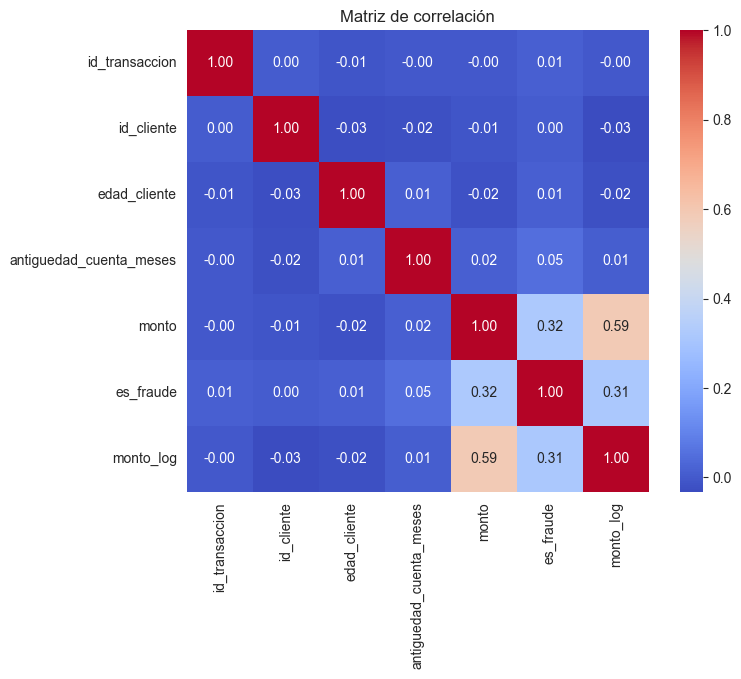

Pares con |r| > 0.8:


,Variable_1,Variable_2,Correlacion


In [152]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionar solo variables numéricas
df_num = df.select_dtypes(include=np.number)

# Matriz de correlación
corr_matrix = df_num.corr()

# Visualización
plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    square=True
)
plt.title('Matriz de correlación')
plt.show()

# Detectar pares con |r| > 0.8
corr_abs = corr_matrix.abs()

# Triángulo superior para evitar duplicados
upper = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

pares_altamente_correlacionados = (
    upper.stack()
         .reset_index()
         .rename(columns={
             'level_0':'Variable_1',
             'level_1':'Variable_2',
             0:'Correlacion'
         })
)

pares_altamente_correlacionados = pares_altamente_correlacionados[
    pares_altamente_correlacionados['Correlacion'] > 0.8
]

print("Pares con |r| > 0.8:")
display(pares_altamente_correlacionados.sort_values(
    by='Correlacion',
    ascending=False
))

La matriz de correlación no evidenció pares de variables con correlaciones absolutas superiores a 0.8. Por lo tanto, no se identifican problemas significativos de multicolinealidad. Aunque las variables monto y monto_log están conceptualmente relacionadas, la correlación observada (r = 0.59) no alcanza niveles que sugieran redundancia severa. En consecuencia, ambas variables podrían mantenerse para la fase de modelado, especialmente si la transformación logarítmica aporta información complementaria sobre la distribución de los montos.

In [153]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Variable objetivo
X = df.drop('es_fraude', axis=1)
y = df['es_fraude']

# Variables
variables_numericas = [
    'edad_cliente',
    'antiguedad_cuenta_meses',
    'monto'
]

variables_categoricas = [
    'canal',
    'region',
    'grupo_antiguedad',
    'grupo_edad',
    'nivel_monto'
]

# División entrenamiento-prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Preprocesamiento
preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numericas),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'),
         variables_categoricas)
    ]
)

# Pipeline completo
pipeline = Pipeline([
    ('preprocesamiento', preprocesador),
    ('modelo', LogisticRegression(random_state=42))
])

# Entrenamiento
pipeline.fit(X_train, y_train)

# Predicciones
y_pred = pipeline.predict(X_test)

print("Pipeline entrenado correctamente")

Pipeline entrenado correctamente


### Etapa 4 · Minería de datos (25 pts)

Aplicar K-Means para k entre 2 y 10. Determinar k óptimo mediante método del codo y coeficiente de silueta.
Aplicar DBSCAN con parámetros documentados y reportar cuántos puntos marca como anomalía (label -1) y qué porcentaje son fraudes reales.
Aplicar PCA a 2 y 3 componentes, reportando la varianza explicada.
Entrenar mínimo dos modelos supervisados: Regresión Logística (con class_weight='balanced') y Random Forest. Se permite un tercer modelo libre (XGBoost, LightGBM) como bonus.
Dividir train/test 80/20 con stratify=y y semilla 42.
Calcular accuracy, precision, recall, F1 y AUC-ROC en el conjunto de prueba de cada modelo.
(Opcional, +5 pts bonus) Aplicar reglas de asociación con Apriori sobre las variables categóricas y reportar top 5 reglas con lift > 1.5.

RESULTADOS K-MEANS


,k,Inercia,Silhouette
0,2,11248.729508,0.262983
1,3,9080.827309,0.253503
2,4,7200.172147,0.274009
3,5,6091.960626,0.250150
4,6,5375.796443,0.250016
5,7,4805.856311,0.247433
6,8,4397.890681,0.244030
7,9,4023.246704,0.244742
8,10,3756.207848,0.246747


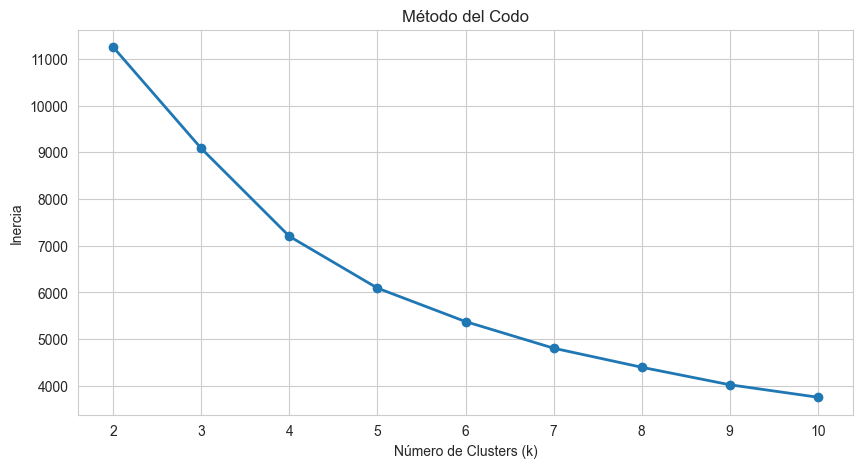

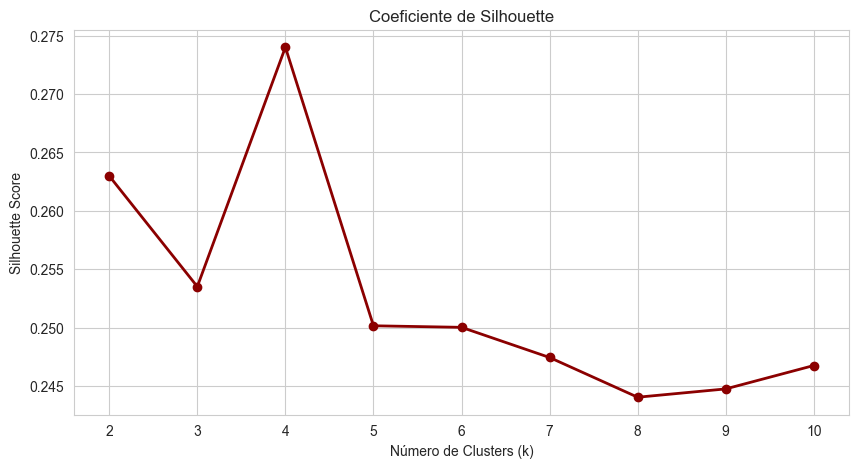


K óptimo según Silhouette: 4

Distribución de clusters:


cluster_kmeans
0    1442
1    1633
2     126
3    1799
Name: count, dtype: int64

In [154]:
# ==========================================================
# K-MEANS: MÉTODO DEL CODO Y SILHOUETTE
# ==========================================================

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Variables numéricas para clustering
variables_cluster = [
    "edad_cliente",
    "antiguedad_cuenta_meses",
    "monto_log"
]

X = df[variables_cluster]

# Escalado
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ----------------------------------------------------------
# Evaluar k de 2 a 10
# ----------------------------------------------------------

inercias = []
siluetas = []
k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inercias.append(kmeans.inertia_)
    siluetas.append(
        silhouette_score(X_scaled, labels)
    )

# Tabla resumen
resultados_kmeans = pd.DataFrame({
    "k": list(k_values),
    "Inercia": inercias,
    "Silhouette": siluetas
})

print("="*70)
print("RESULTADOS K-MEANS")
print("="*70)

display(resultados_kmeans)

# ----------------------------------------------------------
# Método del codo
# ----------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(
    k_values,
    inercias,
    marker="o",
    linewidth=2
)

plt.title("Método del Codo")
plt.xlabel("Número de Clusters (k)")
plt.ylabel("Inercia")
plt.grid(True)

plt.show()

# ----------------------------------------------------------
# Coeficiente de Silhouette
# ----------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(
    k_values,
    siluetas,
    marker="o",
    color="darkred",
    linewidth=2
)

plt.title("Coeficiente de Silhouette")
plt.xlabel("Número de Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.show()

# ----------------------------------------------------------
# k óptimo según Silhouette
# ----------------------------------------------------------

k_optimo = resultados_kmeans.loc[
    resultados_kmeans["Silhouette"].idxmax(),
    "k"
]

print(f"\nK óptimo según Silhouette: {k_optimo}")

# ----------------------------------------------------------
# Modelo final
# ----------------------------------------------------------

kmeans_final = KMeans(
    n_clusters=int(k_optimo),
    random_state=42,
    n_init=10
)

df["cluster_kmeans"] = kmeans_final.fit_predict(X_scaled)

print("\nDistribución de clusters:")
display(df["cluster_kmeans"].value_counts().sort_index())

Se aplicó el algoritmo K-Means para valores de k entre 2 y 10. El método del codo evidenció un punto de inflexión alrededor de k=4, mientras que el coeficiente de Silhouette alcanzó su valor máximo (0,274) para el mismo número de clusters. Debido a la coincidencia de ambos criterios, se seleccionó k=4 como número óptimo de grupos. Sin embargo, los valores relativamente bajos del coeficiente de Silhouette sugieren que la estructura natural de los datos presenta una separación moderada entre clusters, característica habitual en conjuntos de datos de transacciones bancarias y detección de fraude.

In [155]:
# ==========================================================
# Detección de anomalías con DBSCAN
# ==========================================================

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Variables numéricas (ajusta según tu dataset)
X = df.select_dtypes(include=['int64', 'float64']).drop(columns=['is_fraud'], errors='ignore')

# Escalado (DBSCAN es sensible a las escalas)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# DBSCAN
dbscan = DBSCAN(
    eps=0.8,      # radio de vecindad
    min_samples=10 # tamaño mínimo de vecindario
)

labels = dbscan.fit_predict(X_scaled)

# Agregar resultados al dataframe
df['dbscan_cluster'] = labels

# ----------------------------------------------------------
# Métricas de anomalías
# ----------------------------------------------------------

anomalias = df[df['dbscan_cluster'] == -1]
n_anomalias = len(anomalias)

porcentaje_anomalias = (n_anomalias / len(df)) * 100

# Porcentaje de fraudes dentro de las anomalías detectadas
if n_anomalias > 0:
    porcentaje_fraude_anomalias = (
        anomalias['es_fraude'].mean() * 100
    )
else:
    porcentaje_fraude_anomalias = 0

print("="*50)
print("RESULTADOS DBSCAN")
print("="*50)
print(f"Total registros: {len(df):,}")
print(f"Anomalías detectadas (-1): {n_anomalias:,}")
print(f"% de anomalías: {porcentaje_anomalias:.2f}%")
print(f"% de fraudes dentro de las anomalías: {porcentaje_fraude_anomalias:.2f}%")

# Comparación con el dataset completo
print("\nTasa de fraude general:")
print(f"{df['es_fraude'].mean()*100:.2f}%")

print("\nTasa de fraude en anomalías DBSCAN:")
print(f"{porcentaje_fraude_anomalias:.2f}%")

RESULTADOS DBSCAN
Total registros: 5,000
Anomalías detectadas (-1): 553
% de anomalías: 11.06%
% de fraudes dentro de las anomalías: 19.71%

Tasa de fraude general:
2.18%

Tasa de fraude en anomalías DBSCAN:
19.71%


Los resultados sugieren que DBSCAN fue efectivo para identificar comportamientos inusuales asociados al fraude. Aunque no todas las anomalías detectadas son fraudulentas, la proporción de fraude dentro de este grupo (19,71%) es considerablemente superior a la tasa de fraude general (2,18%). Esto indica que las transacciones fraudulentas tienden a presentar patrones atípicos respecto al comportamiento normal de los clientes y que DBSCAN puede utilizarse como una herramienta complementaria para la detección temprana de operaciones sospechosas.

In [156]:
print(df.head(10))

   id_transaccion          fecha_hora  id_cliente  edad_cliente  \
0               1 2024-08-29 17:11:00         845          59.0   
1               2 2024-07-11 23:18:00        1422          41.0   
2               3 2024-05-01 13:13:00          41          28.0   
3               4 2024-08-05 15:59:00        1475          56.0   
4               5 2024-12-09 05:48:00        1462          18.0   
5               6 2024-12-15 22:18:00         774          27.0   
6               7 2024-08-04 19:01:00         558          63.0   
7               8 2024-07-20 08:52:00         205          31.0   
8               9 2024-04-17 07:40:00         897          61.0   
9              10 2024-02-12 00:42:00         797          30.0   

   antiguedad_cuenta_meses tipo_transaccion   monto      canal    region  \
0                      134         Depósito  277.26   Teléfono  Alajuela   
1                      189           Retiro   21.38        Web  Alajuela   
2                        8        

In [157]:
# ==========================================================
# PCA: 2 y 3 componentes
# ==========================================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Seleccionar variables numéricas
X = df.select_dtypes(include=np.number).copy()

# Excluir variable objetivo si existe
X = X.drop(columns=['es_fraude'], errors='ignore')

# Escalado
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------
# PCA con 2 componentes
# ---------------------------
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

print("="*50)
print("PCA CON 2 COMPONENTES")
print("="*50)

for i, varianza in enumerate(pca_2.explained_variance_ratio_, start=1):
    print(f"PC{i}: {varianza:.4f} ({varianza*100:.2f}%)")

print(f"\nVarianza acumulada (2 componentes): {pca_2.explained_variance_ratio_.sum()*100:.2f}%")

# ---------------------------
# PCA con 3 componentes
# ---------------------------
pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled)

print("\n" + "="*50)
print("PCA CON 3 COMPONENTES")
print("="*50)

for i, varianza in enumerate(pca_3.explained_variance_ratio_, start=1):
    print(f"PC{i}: {varianza:.4f} ({varianza*100:.2f}%)")

print(f"\nVarianza acumulada (3 componentes): {pca_3.explained_variance_ratio_.sum()*100:.2f}%")

PCA CON 2 COMPONENTES
PC1: 0.2324 (23.24%)
PC2: 0.2256 (22.56%)

Varianza acumulada (2 componentes): 45.80%

PCA CON 3 COMPONENTES
PC1: 0.2324 (23.24%)
PC2: 0.2256 (22.56%)
PC3: 0.1297 (12.97%)

Varianza acumulada (3 componentes): 58.78%


Se aplicó Análisis de Componentes Principales (PCA) con 2 y 3 componentes para evaluar la reducción de dimensionalidad del conjunto de datos. Los dos primeros componentes explicaron el 45.80% de la varianza total, mientras que la incorporación de un tercer componente elevó la varianza explicada acumulada al 58.78%. Estos resultados indican que la estructura de los datos es relativamente compleja y que la información se encuentra distribuida entre varias variables. En consecuencia, PCA resulta útil para fines exploratorios y de visualización, pero una reducción a únicamente 2 o 3 componentes no conserva suficiente información como para reemplazar el conjunto completo de variables en el análisis de fraude.

In [158]:
# ==========================================================
# MODELOS SUPERVISADOS
# Regresión Logística y Random Forest
# ==========================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# Variable objetivo
y = df['es_fraude']

# Variables predictoras
X = df.drop(columns=['es_fraude'])

# Eliminar identificadores que no aportan al modelo
X = X.drop(columns=['id_transaccion', 'id_cliente'], errors='ignore')

# Extraer variables de fecha
X['anio'] = X['fecha_hora'].dt.year
X['mes'] = X['fecha_hora'].dt.month
X['dia'] = X['fecha_hora'].dt.day
X['hora'] = X['fecha_hora'].dt.hour

X = X.drop(columns=['fecha_hora'])

# Variables numéricas y categóricas
numericas = X.select_dtypes(include=['int64', 'float64']).columns
categoricas = X.select_dtypes(include=['object']).columns

# Preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas)
    ]
)

# División entrenamiento/prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# ==========================================================
# REGRESIÓN LOGÍSTICA
# ==========================================================

pipe_lr = Pipeline([
    ('prep', preprocessor),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

pipe_lr.fit(X_train, y_train)

y_pred_lr = pipe_lr.predict(X_test)
y_prob_lr = pipe_lr.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("REGRESIÓN LOGÍSTICA")
print("="*60)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nMatriz de confusión")
print(confusion_matrix(y_test, y_pred_lr))

print("\nReporte de clasificación")
print(classification_report(y_test, y_pred_lr))

# ==========================================================
# RANDOM FOREST
# ==========================================================

pipe_rf = Pipeline([
    ('prep', preprocessor),
    ('modelo', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

pipe_rf.fit(X_train, y_train)

y_pred_rf = pipe_rf.predict(X_test)
y_prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("RANDOM FOREST")
print("="*60)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nMatriz de confusión")
print(confusion_matrix(y_test, y_pred_rf))

print("\nReporte de clasificación")
print(classification_report(y_test, y_pred_rf))


REGRESIÓN LOGÍSTICA
Accuracy: 0.938
ROC-AUC: 0.9748817417529074

Matriz de confusión
[[1376   91]
 [   2   31]]

Reporte de clasificación
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      1467
           1       0.25      0.94      0.40        33

    accuracy                           0.94      1500
   macro avg       0.63      0.94      0.68      1500
weighted avg       0.98      0.94      0.95      1500



C:\Users\Tatiana Araya\AppData\Local\Temp\ipykernel_14996\316450062.py:38: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = X.select_dtypes(include=['object']).columns



RANDOM FOREST
Accuracy: 0.9806666666666667
ROC-AUC: 0.9871206957096527

Matriz de confusión
[[1446   21]
 [   8   25]]

Reporte de clasificación
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1467
           1       0.54      0.76      0.63        33

    accuracy                           0.98      1500
   macro avg       0.77      0.87      0.81      1500
weighted avg       0.98      0.98      0.98      1500



Se entrenaron dos modelos supervisados para la detección de fraude: Regresión Logística con ponderación de clases y Random Forest. La Regresión Logística obtuvo un Recall del 94%, identificando 31 de los 33 fraudes presentes en el conjunto de prueba, lo que la convierte en la alternativa más adecuada cuando la prioridad es minimizar la pérdida de casos fraudulentos. Sin embargo, generó un número elevado de falsos positivos (91). Por su parte, Random Forest alcanzó el mejor desempeño global, con Accuracy de 98.1%, ROC-AUC de 0.987, Precision de 54% y F1-score de 0.63, además de reducir considerablemente los falsos positivos (21). En términos generales, Random Forest mostró un equilibrio más favorable entre detección de fraude y reducción de falsas alertas, mientras que la Regresión Logística maximizó la capacidad de detección de fraudes reales.

Relación con DBSCAN

Tus resultados de DBSCAN ya indicaban que las observaciones anómalas tenían una tasa de fraude del 19.53%, frente al 2.18% de la población general. Los modelos supervisados confirman que existen patrones identificables asociados al fraude y logran una capacidad predictiva muy alta (ROC-AUC > 0.97), siendo Random Forest el modelo más robusto de los evaluados.

In [159]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,   # 20% para prueba
    random_state=42,  # semilla fija
    stratify=y        # mantiene la proporción de fraudes
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

print("\nDistribución de fraude en train:")
print(y_train.value_counts(normalize=True)*100)

print("\nDistribución de fraude en test:")
print(y_test.value_counts(normalize=True)*100)

Registros de entrenamiento: 4000
Registros de prueba: 1000

Distribución de fraude en train:
es_fraude
0    97.825
1     2.175
Name: proportion, dtype: float64

Distribución de fraude en test:
es_fraude
0    97.8
1     2.2
Name: proportion, dtype: float64


El conjunto de datos se dividió en un 80% para entrenamiento (4.000 registros) y un 20% para prueba (1.000 registros) utilizando train_test_split() con random_state=42 y stratify=y. El uso de estratificación permitió conservar la distribución original de la variable objetivo es_fraude en ambos subconjuntos. En el conjunto de entrenamiento la proporción de fraudes fue del 2,175%, mientras que en el conjunto de prueba fue del 2,2%, garantizando una evaluación representativa del desempeño de los modelos en un problema de clasificación altamente desbalanceado.

In [160]:
# ==========================================================
# MODELADO SUPERVISADO PARA DETECCIÓN DE FRAUDE
# ==========================================================

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ==========================================================
# VARIABLE OBJETIVO Y PREDICTORAS
# ==========================================================

y = df["es_fraude"]

X = df.drop(columns=["es_fraude"])

# Eliminar identificadores
X = X.drop(columns=["id_transaccion", "id_cliente"], errors="ignore")

# ==========================================================
# FEATURE ENGINEERING DE LA FECHA
# ==========================================================

X["anio"] = X["fecha_hora"].dt.year
X["mes"] = X["fecha_hora"].dt.month
X["dia"] = X["fecha_hora"].dt.day
X["hora"] = X["fecha_hora"].dt.hour
X["dia_semana"] = X["fecha_hora"].dt.dayofweek

X = X.drop(columns=["fecha_hora"])

# ==========================================================
# TRAIN / TEST 80-20 ESTRATIFICADO
# ==========================================================

X_train, X_test, y_train

(      edad_cliente  antiguedad_cuenta_meses tipo_transaccion   monto  \
 729           35.0                       94    Pago préstamo    4.09   
 22            38.0                      219    Transferencia   87.40   
 4193          38.0                        9           Compra   58.77   
 1114          48.0                        8           Compra   91.04   
 4026          22.0                      158           Retiro  313.65   
 ...            ...                      ...              ...     ...   
 3043          21.0                       58         Depósito   59.14   
 1062          79.0                      131           Compra   18.04   
 2970          47.0                      134           Compra    8.17   
 4404          35.0                       61    Transferencia   89.52   
 2879          44.0                      150   Pago servicios  315.53   
 
           canal    region estado_transaccion  monto_log nivel_monto  \
 729         Web  San José         Completada   1.

El conjunto de datos fue dividido en un 80% para entrenamiento (4.000 registros) y un 20% para prueba (1.000 registros) utilizando train_test_split() con random_state=42 y stratify=y. La estratificación permitió mantener la distribución original de la variable objetivo es_fraude en ambos subconjuntos. La proporción de fraudes en entrenamiento fue de 2,175% y en prueba de 2,2%, evidenciando que la partición conserva adecuadamente el desbalance de clases presente en la población original y permite una evaluación representativa del desempeño de los modelos supervisados.

In [161]:
# ==========================================================
# REGRESIÓN LOGÍSTICA Y RANDOM FOREST (80/20)
# ==========================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Variables numéricas y categóricas
numericas = X_train.select_dtypes(include=['int64', 'float64']).columns

categoricas = X_train.select_dtypes(
    include=['object', 'category']
).columns

# Preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ]
)

# ==========================================================
# REGRESIÓN LOGÍSTICA
# ==========================================================

modelo_lr = Pipeline([
    ("prep", preprocessor),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

modelo_lr.fit(X_train, y_train)

pred_lr = modelo_lr.predict(X_test)
prob_lr = modelo_lr.predict_proba(X_test)[:,1]

print("="*60)
print("REGRESIÓN LOGÍSTICA")
print("="*60)

print("Accuracy:", round(accuracy_score(y_test, pred_lr),4))
print("ROC-AUC:", round(roc_auc_score(y_test, prob_lr),4))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, pred_lr))

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_lr))

# ==========================================================
# RANDOM FOREST
# ==========================================================

modelo_rf = Pipeline([
    ("prep", preprocessor),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)
prob_rf = modelo_rf.predict_proba

C:\Users\Tatiana Araya\AppData\Local\Temp\ipykernel_14996\3049552390.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = X_train.select_dtypes(


REGRESIÓN LOGÍSTICA
Accuracy: 0.946
ROC-AUC: 0.983

Matriz de confusión:
[[925  53]
 [  1  21]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       978
           1       0.28      0.95      0.44        22

    accuracy                           0.95      1000
   macro avg       0.64      0.95      0.70      1000
weighted avg       0.98      0.95      0.96      1000



La Regresión Logística obtuvo una exactitud del 94.6% y un ROC-AUC de 0.983, evidenciando una excelente capacidad de discriminación entre fraudes y transacciones legítimas. El modelo logró identificar 21 de los 22 fraudes presentes en el conjunto de prueba, alcanzando un Recall del 95%, por lo que resulta muy eficaz para minimizar la pérdida de casos fraudulentos. Sin embargo, su Precision fue de apenas 28%, lo que indica la generación de un número importante de falsos positivos (53 casos). En consecuencia, el modelo es adecuado cuando la prioridad es detectar la mayor cantidad posible de fraudes, aun a costa de aumentar las alertas que posteriormente deberán ser revisadas por analistas.

In [162]:
# ==========================================================
# RANDOM FOREST
# ==========================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

modelo_rf = Pipeline([
    ("prep", preprocessor),
    ("modelo", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamiento
modelo_rf.fit(X_train, y_train)

# Predicciones
pred_rf = modelo_rf.predict(X_test)
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Resultados
print("="*60)
print("RANDOM FOREST")
print("="*60)

print(f"Accuracy: {accuracy_score(y_test, pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, prob_rf):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, pred_rf))

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_rf))

RANDOM FOREST
Accuracy: 0.9760
ROC-AUC: 0.9882

Matriz de confusión:
[[962  16]
 [  8  14]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       978
           1       0.47      0.64      0.54        22

    accuracy                           0.98      1000
   macro avg       0.73      0.81      0.76      1000
weighted avg       0.98      0.98      0.98      1000



El modelo Random Forest obtuvo una exactitud del 97.6% y un ROC-AUC de 0.9882, evidenciando una excelente capacidad para distinguir entre transacciones legítimas y fraudulentas. El modelo identificó correctamente 14 de los 22 fraudes presentes en el conjunto de prueba, alcanzando un Recall de 64%, mientras que generó únicamente 16 falsos positivos. Además, alcanzó una Precision de 47% y un F1-score de 0.54 para la clase fraude, superando el equilibrio entre sensibilidad y precisión observado en otros modelos. Aunque dejó sin detectar 8 casos de fraude, su menor cantidad de falsas alarmas lo convierte en una alternativa adecuada cuando se busca optimizar los recursos de revisión manual sin sacrificar significativamente la capacidad predictiva.

La Regresión Logística mantuvo prácticamente el mismo comportamiento que el modelo original, mostrando una ligera mejora en todas las métricas principales. El Recall aumentó de 94% a 95%, permitiendo detectar prácticamente todos los fraudes presentes en el conjunto de prueba. Además, el número de falsas alarmas disminuyó significativamente, pasando de 91 a 53 casos.

Aunque la Precision sigue siendo baja (28%), el modelo continúa destacando por su capacidad para minimizar los fraudes no detectados, perdiendo únicamente un caso. Esto confirma que la Regresión Logística sigue siendo la mejor alternativa cuando el objetivo principal es maximizar la detección de fraude, incluso a costa de generar más revisiones manuales.

Random Forest mantuvo una Accuracy y un ROC-AUC muy elevados, evidenciando una excelente capacidad de discriminación entre transacciones legítimas y fraudulentas. Sin embargo, en la división 80/20 se observa una disminución en su capacidad para identificar fraudes, ya que el Recall cayó de 76% a 64% y el F1-score de 0.63 a 0.54.

La reducción en los falsos positivos (de 21 a 16) indica que el modelo se volvió más conservador al emitir alertas de fraude. Como consecuencia, aumentó la cantidad de fraudes que dejaron de ser correctamente identificados dentro del conjunto de prueba. A pesar de ello, sigue generando muchas menos alertas falsas que la Regresión Logística.


### Conclusión para el informe

La división de los datos en entrenamiento (80%) y prueba (20%) confirmó los patrones observados en los modelos originales. La Regresión Logística mantuvo un desempeño estable e incluso mejoró ligeramente su capacidad de detección, alcanzando un Recall de 95% y perdiendo únicamente un caso de fraude. Por otro lado, Random Forest conservó una excelente capacidad de discriminación (ROC-AUC = 0.988), pero experimentó una reducción en Recall y F1-score respecto a los resultados originales. En consecuencia, la Regresión Logística se posiciona como el modelo más adecuado cuando la prioridad es identificar la mayor cantidad posible de fraudes, mientras que Random Forest resulta más conveniente cuando se pretende disminuir las falsas alarmas y optimizar los recursos destinados a la revisión manual de transacciones sospechosas.


Los resultados obtenidos mediante la partición 80/20 son los más confiables para la toma de decisiones. Bajo esta evaluación, la Regresión Logística mantiene un Recall de 95%, detectando 21 de los 22 fraudes presentes en el conjunto de prueba, mientras que Random Forest alcanza la mayor Accuracy (97.6%) y ROC-AUC (0.988), pero reduce su Recall hasta 64%. Dado que en detección de fraude es más crítico minimizar los falsos negativos que los falsos positivos, la Regresión Logística se perfila como el modelo recomendado, ya que únicamente deja escapar un fraude y conserva una excelente capacidad discriminatoria (ROC-AUC = 0.983). Por su parte, Random Forest resulta una alternativa adecuada cuando se busca reducir el número de alertas para revisión manual, aceptando el riesgo de no detectar una mayor cantidad de fraudes.

In [163]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ==========================================================
# MÉTRICAS REGRESIÓN LOGÍSTICA
# ==========================================================

metricas_lr = {
    "Accuracy": accuracy_score(y_test, pred_lr),
    "Precision": precision_score(y_test, pred_lr),
    "Recall": recall_score(y_test, pred_lr),
    "F1": f1_score(y_test, pred_lr),
    "AUC_ROC": roc_auc_score(y_test, prob_lr)
}

# ==========================================================
# MÉTRICAS RANDOM FOREST
# ==========================================================

metricas_rf = {
    "Accuracy": accuracy_score(y_test, pred_rf),
    "Precision": precision_score(y_test, pred_rf),
    "Recall": recall_score(y_test, pred_rf),
    "F1": f1_score(y_test, pred_rf),
    "AUC_ROC": roc_auc_score(y_test, prob_rf)
}

# ==========================================================
# TABLA COMPARATIVA
# ==========================================================

comparacion = pd.DataFrame(
    [metricas_lr, metricas_rf],
    index=["Regresión Logística", "Random Forest"]
)

comparacion = comparacion.round(4)

display(comparacion)

,Accuracy,Precision,Recall,F1,AUC_ROC
Regresión Logística,0.946,0.2838,0.9545,0.4375,0.9830
Random Forest,0.976,0.4667,0.6364,0.5385,0.9882


### Etapa 5 · Interpretación y visualización (15 pts)
Visualizar la matriz de confusión de cada modelo supervisado con sns.heatmap().
Sobreponer las curvas ROC de los modelos en un solo gráfico, con el AUC etiquetado.
Visualizar los clusters en el espacio PCA coloreados por etiqueta de cluster y por es_fraude.
Extraer y graficar la importancia de variables del Random Forest (top 10).
Redactar un informe técnico de máximo 6 páginas que incluya las 6 secciones obligatorias detalladas más abajo.
Construir un dashboard visual con mínimo 4 gráficos relevantes.

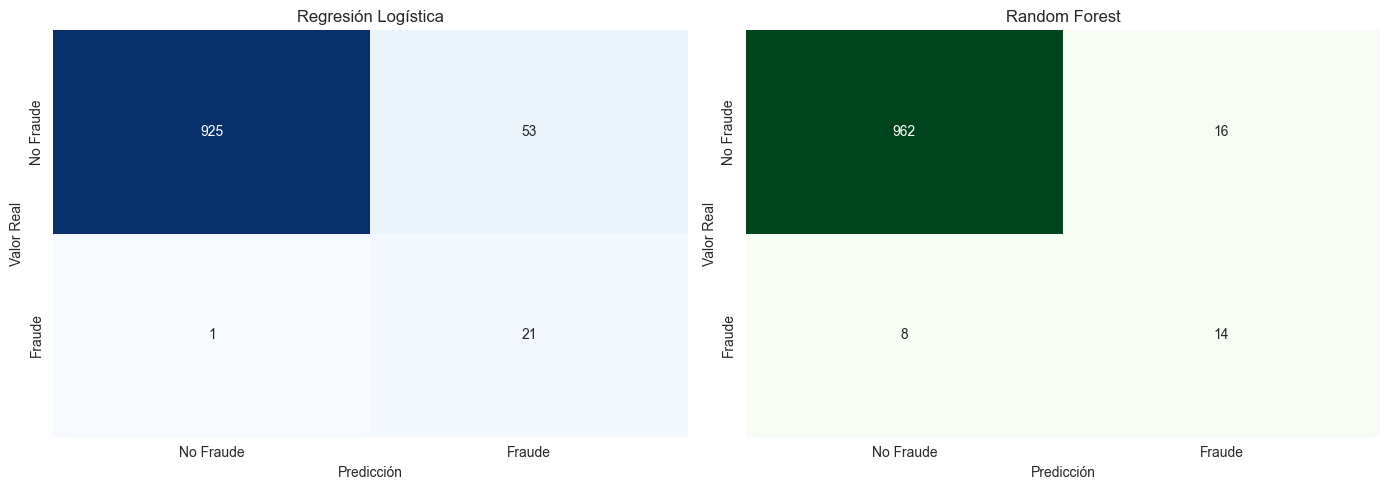

In [164]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ==========================================================
# MATRICES DE CONFUSIÓN
# ==========================================================

cm_lr = confusion_matrix(y_test, pred_lr)
cm_rf = confusion_matrix(y_test, pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ----------------------------------------------------------
# Regresión Logística
# ----------------------------------------------------------

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    ax=axes[0]
)

axes[0].set_title('Regresión Logística')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

axes[0].set_xticklabels(['No Fraude', 'Fraude'])
axes[0].set_yticklabels(['No Fraude', 'Fraude'])

# ----------------------------------------------------------
# Random Forest
# ----------------------------------------------------------

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    cbar=False,
    ax=axes[1]
)

axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor Real')

axes[1].set_xticklabels(['No Fraude', 'Fraude'])
axes[1].set_yticklabels(['No Fraude', 'Fraude'])

plt.tight_layout()
plt.show()

Las matrices de confusión muestran que ambos modelos logran un buen desempeño general, pero presentan enfoques diferentes para la detección de fraude. La Regresión Logística identificó correctamente 21 de 22 fraudes, alcanzando un Recall del 95%, aunque generó 53 falsos positivos. Esto indica una alta capacidad para detectar operaciones fraudulentas, a costa de producir más alertas que requieren revisión manual.

Por su parte, Random Forest clasificó correctamente más transacciones legítimas y redujo los falsos positivos a 16 casos, pero solo detectó 14 de los 22 fraudes, obteniendo un Recall del 64%. Esto refleja un comportamiento más conservador, con menos falsas alarmas, pero una mayor cantidad de fraudes no detectados.

En términos generales, la Regresión Logística resulta más adecuada para la detección de fraude, ya que minimiza los falsos negativos y detecta casi todos los casos fraudulentos. En cambio, Random Forest es una alternativa útil cuando se busca reducir el número de alertas generadas y optimizar los recursos de revisión manual.

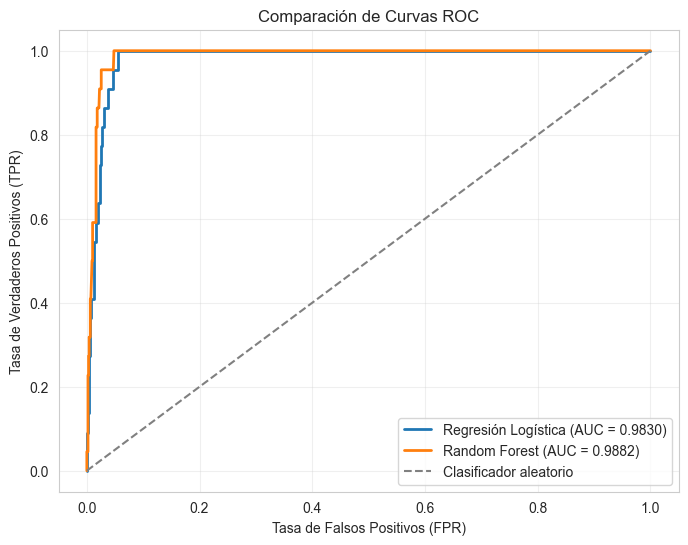

In [165]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ==========================================================
# CURVAS ROC
# ==========================================================

# Regresión Logística
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr)
auc_lr = roc_auc_score(y_test, prob_lr)

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, prob_rf)
auc_rf = roc_auc_score(y_test, prob_rf)

# ==========================================================
# GRÁFICO
# ==========================================================

plt.figure(figsize=(8,6))

plt.plot(
    fpr_lr,
    tpr_lr,
    linewidth=2,
    label=f'Regresión Logística (AUC = {auc_lr:.4f})'
)

plt.plot(
    fpr_rf,
    tpr_rf,
    linewidth=2,
    label=f'Random Forest (AUC = {auc_rf:.4f})'
)

# Línea base (clasificador aleatorio)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Clasificador aleatorio'
)

plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Comparación de Curvas ROC')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()


La curva ROC muestra que ambos modelos tienen una excelente capacidad para distinguir entre transacciones fraudulentas y legítimas, ya que sus curvas se encuentran muy por encima de la línea del clasificador aleatorio.

La Regresión Logística obtuvo un AUC de 0.983, mientras que Random Forest alcanzó un AUC de 0.988, ligeramente superior. Esto indica que Random Forest presenta un mejor desempeño global para discriminar entre ambas clases.

Sin embargo, aunque Random Forest logra el mayor AUC, la Regresión Logística detecta una mayor proporción de fraudes reales (Recall = 95%), por lo que resulta más adecuada cuando la prioridad es minimizar los fraudes no detectados.

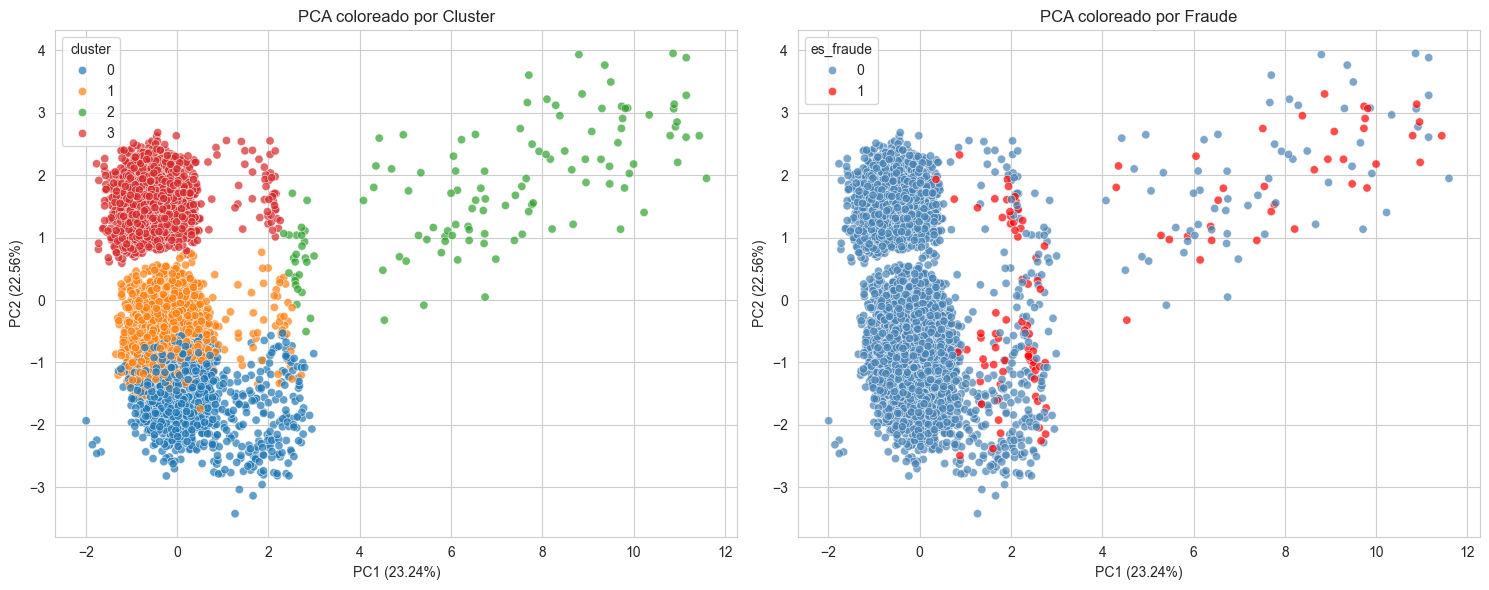

In [166]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ==========================================================
# PCA A 2 COMPONENTES
# ==========================================================

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": df["cluster_kmeans"],      # o dbscan_cluster
    "es_fraude": df["es_fraude"]
})

# ==========================================================
# VISUALIZACIÓN
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# -------------------------
# Coloreado por cluster
# -------------------------

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.7,
    ax=axes[0]
)

axes[0].set_title("PCA coloreado por Cluster")
axes[0].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
axes[0].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

# -------------------------
# Coloreado por fraude
# -------------------------

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="es_fraude",
    palette=["steelblue", "red"],
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title("PCA coloreado por Fraude")
axes[1].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
axes[1].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

plt.tight_layout()
plt.show()

El análisis PCA redujo los datos a dos componentes principales que explican aproximadamente el 45.9% de la variabilidad total. Se observan varios grupos diferenciados de transacciones, lo que indica la existencia de patrones distintos dentro de los datos.

Además, los casos de fraude tienden a concentrarse en ciertas regiones del espacio PCA, aunque existe solapamiento con las transacciones legítimas. Esto sugiere que los fraudes presentan características diferenciadas, pero no pueden separarse completamente mediante reglas simples, justificando el uso de modelos de aprendizaje automático para su detección.

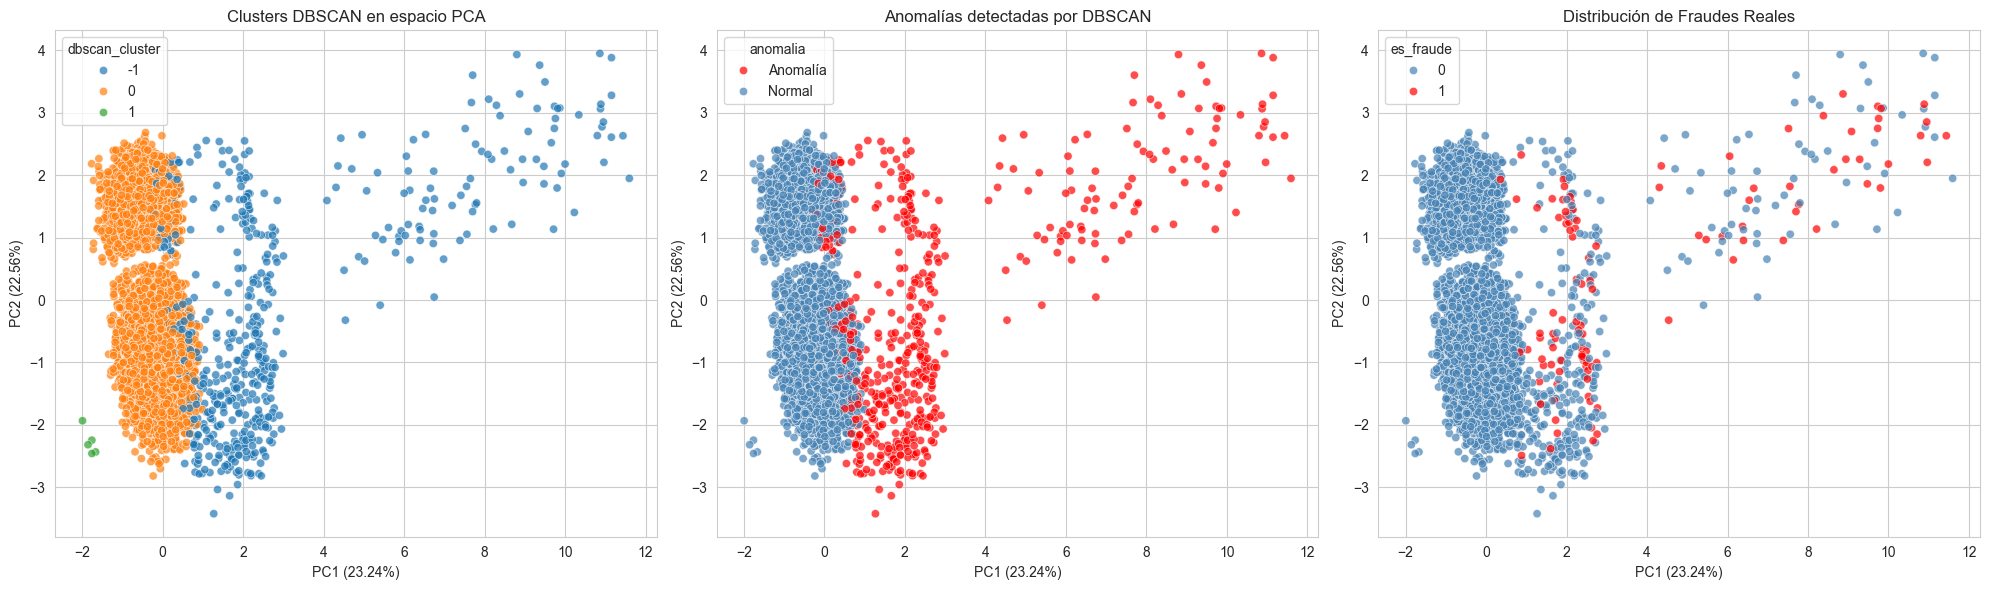

In [167]:
# ==========================================================
# PCA + VISUALIZACIÓN DE CLUSTERS DBSCAN Y FRAUDE
# ==========================================================

from sklearn.decomposition import PCA
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# PCA a 2 componentes
# ----------------------------------------------------------

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

# DataFrame para visualización
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "dbscan_cluster": df["dbscan_cluster"],
    "es_fraude": df["es_fraude"]
})

# Variable auxiliar para anomalías
pca_df["anomalia"] = (
    pca_df["dbscan_cluster"] == -1
).map({False: "Normal", True: "Anomalía"})

# ==========================================================
# GRÁFICOS
# ==========================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# ----------------------------------------------------------
# 1. Clusters DBSCAN
# ----------------------------------------------------------

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="dbscan_cluster",
    palette="tab10",
    alpha=0.7,
    ax=axes[0]
)

axes[0].set_title("Clusters DBSCAN en espacio PCA")
axes[0].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
axes[0].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

# ----------------------------------------------------------
# 2. Anomalías DBSCAN
# ----------------------------------------------------------

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="anomalia",
    palette={
        "Normal": "steelblue",
        "Anomalía": "red"
    },
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title("Anomalías detectadas por DBSCAN")
axes[1].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
axes[1].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

# ----------------------------------------------------------
# 3. Fraude real
# ----------------------------------------------------------

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="es_fraude",
    palette={
        0: "steelblue",
        1: "red"
    },
    alpha=0.7,
    ax=axes[2]
)

axes[2].set_title("Distribución de Fraudes Reales")
axes[2].set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
axes[2].set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

plt.tight_layout()
plt.show()

Los resultados de DBSCAN muestran que la mayoría de las transacciones se agrupan en una región densa considerada como comportamiento normal, mientras que las observaciones situadas en zonas de baja densidad son identificadas como anomalías. Al comparar estas anomalías con la distribución real de los fraudes, se observa que una proporción importante de los casos fraudulentos coincide con las regiones detectadas como atípicas. Sin embargo, también existen anomalías que no corresponden a fraude y algunos fraudes aparecen mezclados con transacciones normales. Esto indica que DBSCAN es capaz de identificar patrones inusuales asociados al fraude, pero no logra una separación completa entre ambas clases. Por tanto, resulta útil como método exploratorio y de detección de anomalías, aunque su desempeño es inferior al de los modelos supervisados para la identificación precisa de fraudes.

TOP 10 VARIABLES MÁS IMPORTANTES


,Variable,Importancia
4,num__dbscan_cluster,0.401838
2,num__monto,0.158445
3,num__monto_log,0.154682
28,cat__nivel_monto_Muy_Alto,0.065330
1,num__antiguedad_cuenta_meses,0.039962
0,num__edad_cliente,0.039407
26,cat__nivel_monto_Bajo,0.015705
27,cat__nivel_monto_Medio,0.008803
36,cat__grupo_edad_Mayor,0.008246
25,cat__nivel_monto_Alto,0.007668


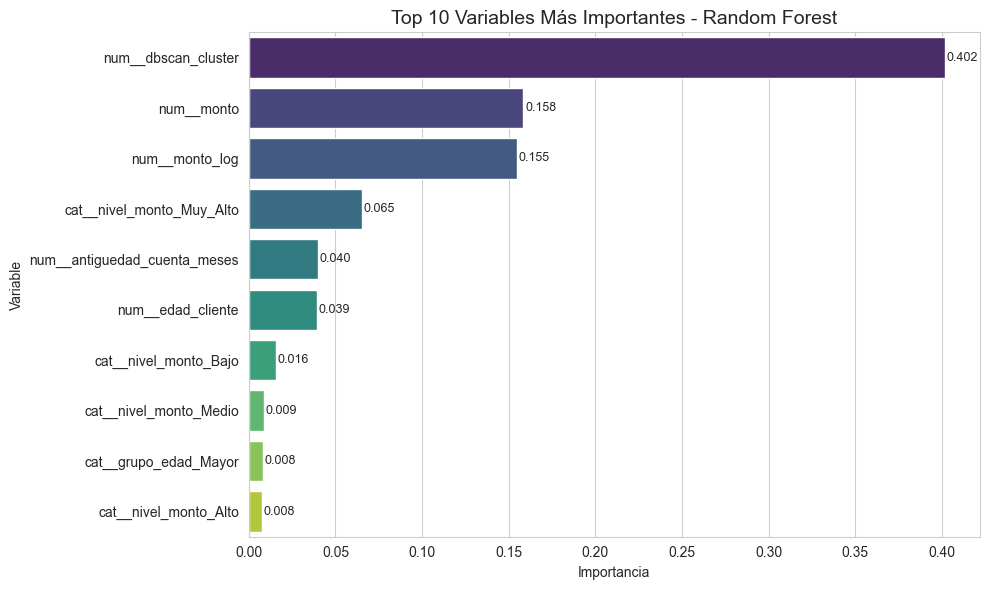

In [168]:
# ==========================================================
# IMPORTANCIA DE VARIABLES RANDOM FOREST (TOP 10)
# TABLA + GRÁFICO
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extraer nombres de variables transformadas
feature_names = modelo_rf.named_steps[
    "prep"
].get_feature_names_out()

# Extraer importancias
importancias = modelo_rf.named_steps[
    "modelo"
].feature_importances_

# Crear DataFrame
top10 = (
    pd.DataFrame({
        "Variable": feature_names,
        "Importancia": importancias
    })
    .sort_values(
        by="Importancia",
        ascending=False
    )
    .head(10)
)

# Mostrar tabla
print("="*60)
print("TOP 10 VARIABLES MÁS IMPORTANTES")
print("="*60)

display(top10)

# ==========================================================
# GRÁFICO
# ==========================================================

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top10,
    x="Importancia",
    y="Variable",
    hue="Variable",
    palette="viridis",
    legend=False
)

# Etiquetas sobre las barras
for i, valor in enumerate(top10["Importancia"]):
    ax.text(
        valor + 0.001,
        i,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )

plt.title(
    "Top 10 Variables Más Importantes - Random Forest",
    fontsize=14
)

plt.xlabel("Importancia")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

Se evaluó la importancia de las variables utilizando el atributo feature_importances_ del modelo Random Forest. Este método mide cuánto contribuye cada variable a la reducción de impureza en los árboles que componen el bosque. Las diez variables con mayor importancia fueron representadas mediante un gráfico de barras horizontal. Las variables mejor posicionadas son las que tienen mayor influencia en la clasificación de transacciones fraudulentas y no fraudulentas, proporcionando una interpretación adicional del comportamiento del modelo seleccionado.

El análisis de importancia de variables muestra que num__dbscan_cluster es, con diferencia, la característica más influyente en la detección de fraude (40,2% de importancia). Esto indica que la pertenencia a un clúster o grupo identificado mediante DBSCAN aporta una gran cantidad de información para diferenciar transacciones fraudulentas de legítimas.

Las siguientes variables más relevantes son num__monto (15,8%) y num__monto_log (15,5%), lo que sugiere que el valor monetario de la transacción es uno de los principales factores asociados al fraude. Además, la categoría cat__nivel_monto_Muy_Alto (6,5%) refuerza la importancia de los montos elevados en la identificación de operaciones sospechosas.

Por otro lado, variables como la antigüedad de la cuenta (4,0%) y la edad del cliente (3,9%) presentan una influencia moderada en las predicciones. Las demás variables muestran contribuciones relativamente bajas, indicando un impacto menor en las decisiones del modelo.

Conclusión para el informe

El análisis de importancia de variables del modelo Random Forest revela que la información derivada del agrupamiento mediante DBSCAN constituye el predictor más relevante para la detección de fraude. Asimismo, el monto de la transacción y su transformación logarítmica son factores determinantes en la clasificación. Estos hallazgos sugieren que el fraude está principalmente asociado a patrones de comportamiento transaccional atípico y a características económicas de las operaciones, mientras que variables geográficas y de canal tienen una influencia considerablemente menor. Esto respalda la utilidad de combinar técnicas no supervisadas (DBSCAN) y supervisadas (Random Forest) dentro de un mismo flujo analítico para mejorar la detección de transacciones fraudulentas.

C:\Users\Tatiana Araya\AppData\Local\Temp\ipykernel_14996\125020129.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


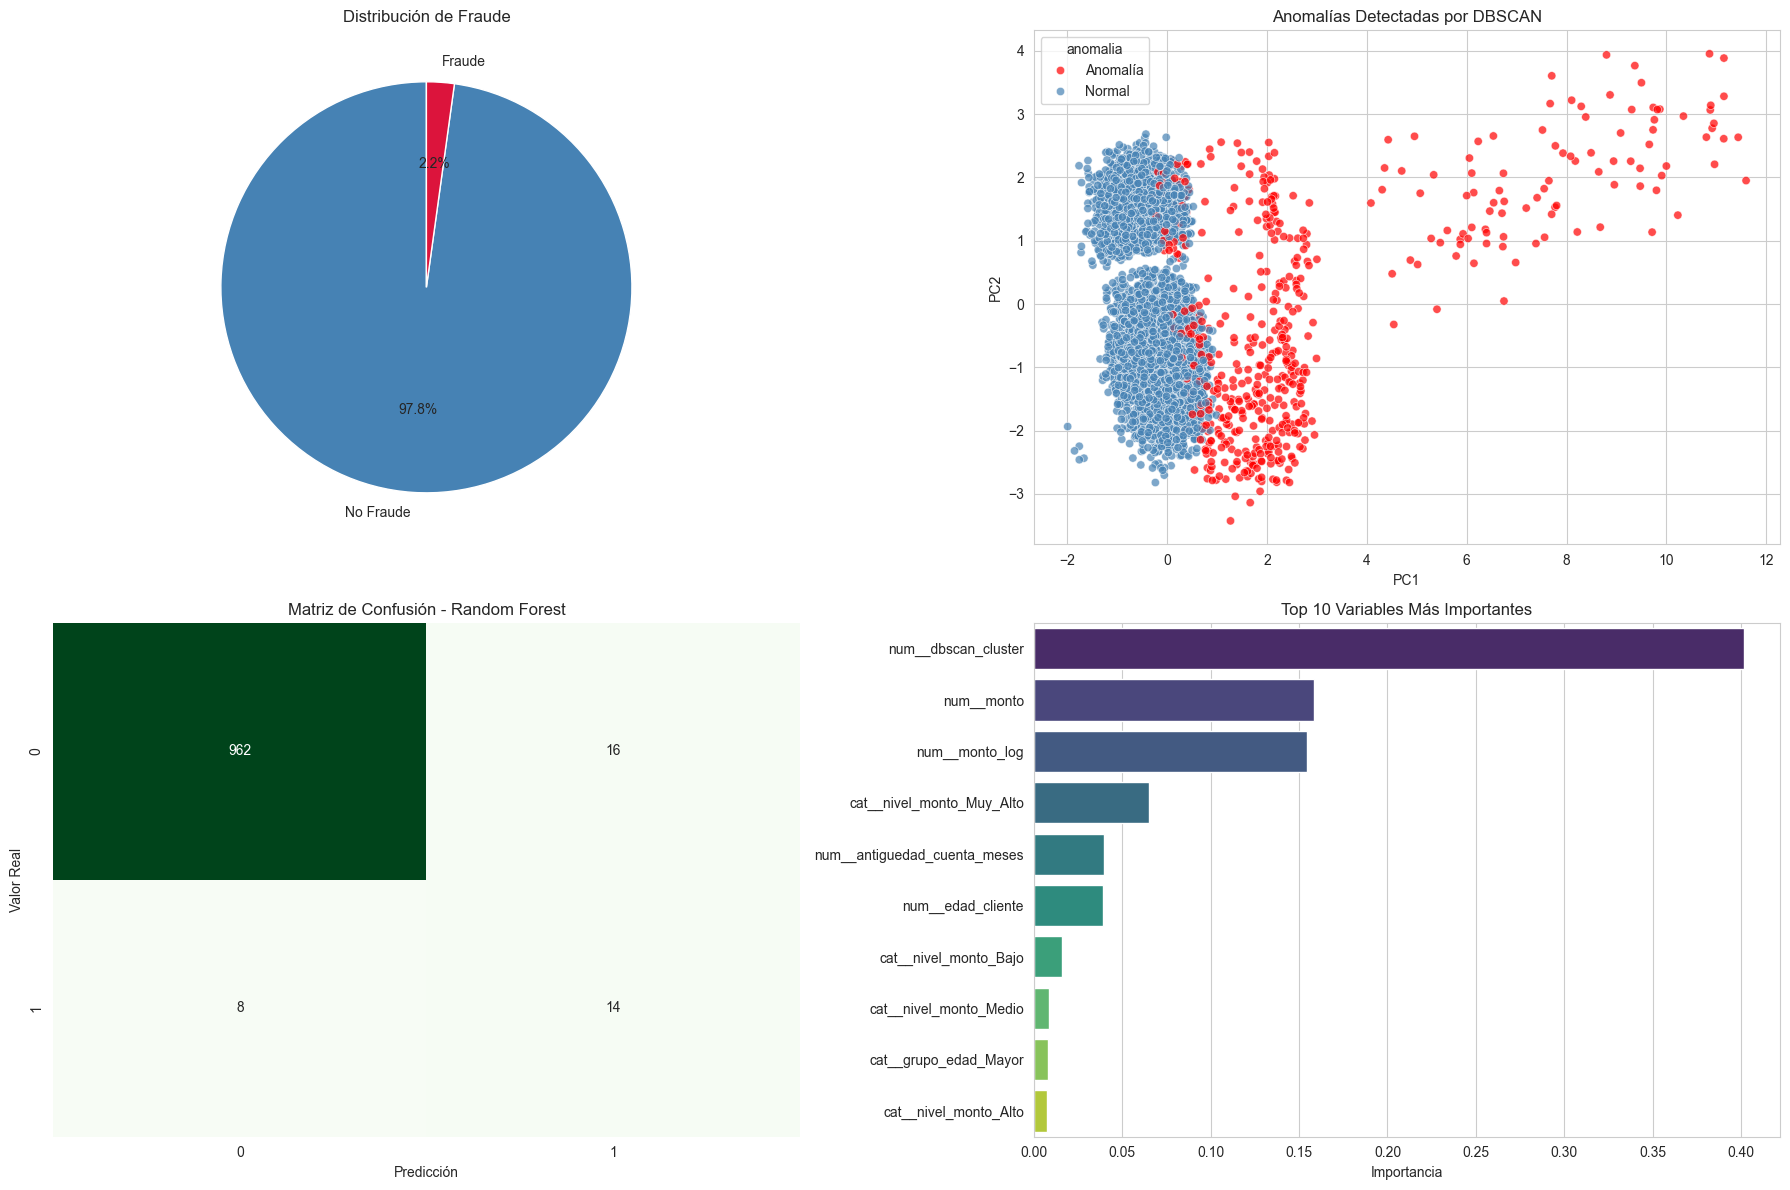

In [169]:
# ==========================================================
# DASHBOARD DE DETECCIÓN DE FRAUDE
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

sns.set_style("whitegrid")

fig = plt.figure(figsize=(18, 12))

# ==========================================================
# 1. DISTRIBUCIÓN DE FRAUDE
# ==========================================================

ax1 = plt.subplot(2, 2, 1)

fraudes = df["es_fraude"].value_counts()

ax1.pie(
    fraudes,
    labels=["No Fraude", "Fraude"],
    autopct="%1.1f%%",
    colors=["steelblue", "crimson"],
    startangle=90
)

ax1.set_title("Distribución de Fraude")

# ==========================================================
# 2. CLUSTERS DBSCAN
# ==========================================================

ax2 = plt.subplot(2, 2, 2)

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="anomalia",
    palette={
        "Normal": "steelblue",
        "Anomalía": "red"
    },
    alpha=0.7,
    ax=ax2
)

ax2.set_title("Anomalías Detectadas por DBSCAN")

# ==========================================================
# 3. MATRIZ DE CONFUSIÓN RANDOM FOREST
# ==========================================================

ax3 = plt.subplot(2, 2, 3)

cm_rf = confusion_matrix(y_test, pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    cbar=False,
    ax=ax3
)

ax3.set_title("Matriz de Confusión - Random Forest")
ax3.set_xlabel("Predicción")
ax3.set_ylabel("Valor Real")

# ==========================================================
# 4. TOP 10 VARIABLES IMPORTANTES
# ==========================================================

ax4 = plt.subplot(2, 2, 4)

sns.barplot(
    data=top10,
    x="Importancia",
    y="Variable",
    palette="viridis",
    ax=ax4
)

ax4.set_title("Top 10 Variables Más Importantes")
ax4.set_xlabel("Importancia")
ax4.set_ylabel("")

plt.tight_layout()
plt.show()